# 01 — Exploración de datos

Este notebook documenta el EDA de los tres datasets sample públicos del Asistente IA DINDES.
Los datos son sintéticos y académicos.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

DATA = ROOT / "data"

docs = pd.read_csv(DATA / "Dataset_1_Documentacion_Tecnica_DINDES_Sample.csv")
inv = pd.read_csv(DATA / "Dataset_2_Inventario_Institucional_DINDES_Sample.csv")
qa = pd.read_csv(DATA / "Dataset_3_Evaluacion_QA_Asistente_IA_Sample.csv")

print("Raíz del proyecto:", ROOT)
print("Documentos:", docs.shape)
print("Inventario:", inv.shape)
print("QA:", qa.shape)


Raíz del proyecto: c:\Proyectos\Asistente_IA
Documentos: (8, 12)
Inventario: (10, 11)
QA: (10, 9)


In [2]:
display(docs.head())
display(inv.head())
display(qa.head())


,document_id,project_id,document_type,title,responsible_unit,document_date,version,section,chunk_id,text,source_status,access_level
0,DOC-001,PROY-001,Informe técnico,Simulador Táctico Submarino - Informe de Arqui...,DINDES,2025-03-15,1.0,Arquitectura del sistema,DOC-001-C001,"El sistema integra estaciones de instructor, v...",vigente,autorizado
1,DOC-002,PROY-002,Especificación técnica,Simulador de Navegación y Ataque - Requisitos,DINDES,2025-06-10,2.1,Requisitos funcionales,DOC-002-C001,"El simulador debe representar navegación, dete...",vigente,autorizado
2,DOC-003,PROY-003,Manual,Procedimiento de mantenimiento de estación de ...,DINDES,2024-11-20,1.2,Mantenimiento preventivo,DOC-003-C001,El mantenimiento preventivo incluye inspección...,vigente,autorizado
3,DOC-004,PROY-004,Informe de pruebas,Pruebas de integración del sistema de comunica...,DINDES,2025-08-05,1.0,Resultados,DOC-004-C001,"Las pruebas verificaron transmisión de datos, ...",vigente,autorizado
4,DOC-005,PROY-005,Informe técnico,Lecciones aprendidas del desarrollo de prototipos,DINDES,2026-01-18,1.0,Lecciones aprendidas,DOC-005-C001,La reutilización de componentes disponibles re...,vigente,autorizado


,codigo,descripcion,categoria,marca,modelo,cantidad,unidad,estado,ubicacion,responsable,fecha_actualizacion
0,INV-0001,Computador de alto rendimiento,Computación,Intel/ASUS,Workstation IA,2,unidad,Operativo,Laboratorio IA,DINDES,2026-09-15
1,INV-0002,GPU para procesamiento IA,Computación,NVIDIA,RTX 5080 16GB,2,unidad,Operativo,Laboratorio IA,DINDES,2026-09-15
2,INV-0003,Osciloscopio digital,Instrumentación,Keysight,DSOX-series,1,unidad,Operativo,Laboratorio Electrónica,DINDES,2026-09-10
3,INV-0004,Analizador de espectro,Instrumentación,Rohde & Schwarz,FPC-series,1,unidad,Operativo,Laboratorio RF,DINDES,2026-09-10
4,INV-0005,Generador de señales,Instrumentación,Siglent,SDG-series,1,unidad,Operativo,Laboratorio RF,DINDES,2026-09-10


,qa_id,question,category,expected_source_id,expected_answer,acceptable_answer,difficulty,answerable,notes
0,QA-001,¿Qué componentes principales integra la arquit...,arquitectura,DOC-001,"Integra estaciones de instructor, visualizació...","Debe mencionar estaciones de instructor, visua...",media,si,Respuesta sustentada en documento técnico.
1,QA-002,¿Qué funciones debe representar el Simulador d...,requisitos,DOC-002,"Debe representar navegación, detección de cont...","Debe incluir navegación, detección de contacto...",media,si,Consulta documental.
2,QA-003,¿Qué actividades contempla el mantenimiento pr...,mantenimiento,DOC-003,"Incluye inspección de conexiones, limpieza, ve...",Debe mencionar al menos tres actividades.,baja,si,Consulta factual.
3,QA-004,¿Qué se verificó durante las pruebas del siste...,pruebas,DOC-004,"Se verificó transmisión de datos, continuidad ...",Debe mencionar los tres aspectos principales.,media,si,Consulta sobre resultados.
4,QA-005,¿Qué ventaja y qué precaución se identificaron...,lecciones_aprendidas,DOC-005,"Reduce tiempos de adquisición, pero se debe ve...",Debe contener la ventaja y la precaución.,media,si,Pregunta de síntesis.


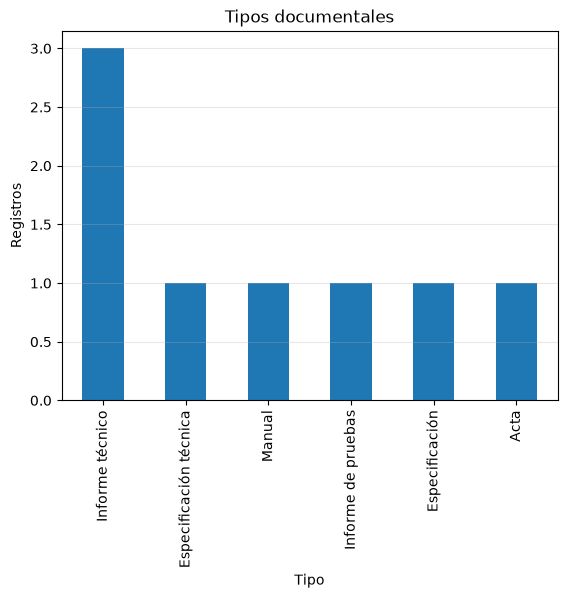

In [3]:
# Gráfico 1: tipos documentales
docs["document_type"].value_counts().plot(kind="bar", title="Tipos documentales")
plt.xlabel("Tipo")
plt.ylabel("Registros")
plt.grid(axis="y", alpha=.3)
plt.show()


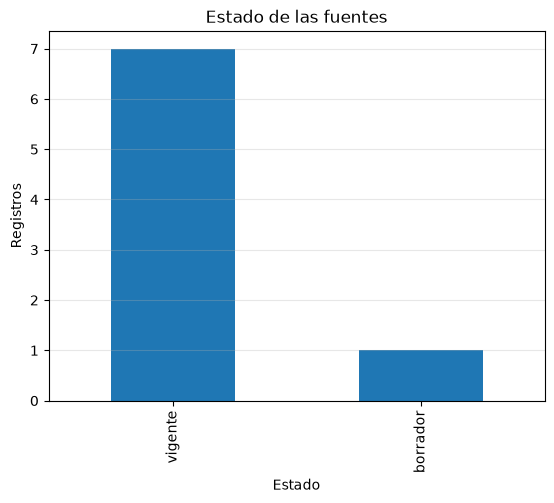

In [4]:
# Gráfico 2: estado de las fuentes
docs["source_status"].value_counts().plot(kind="bar", title="Estado de las fuentes")
plt.xlabel("Estado")
plt.ylabel("Registros")
plt.grid(axis="y", alpha=.3)
plt.show()


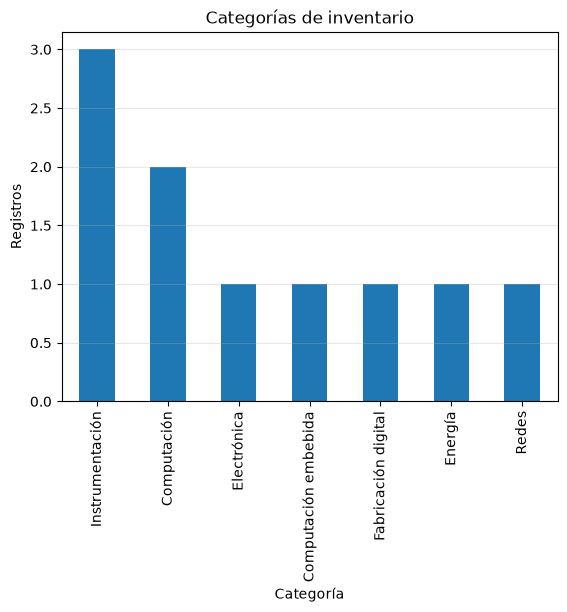

In [5]:
# Gráfico 3: categorías de inventario
inv["categoria"].value_counts().plot(kind="bar", title="Categorías de inventario")
plt.xlabel("Categoría")
plt.ylabel("Registros")
plt.grid(axis="y", alpha=.3)
plt.show()


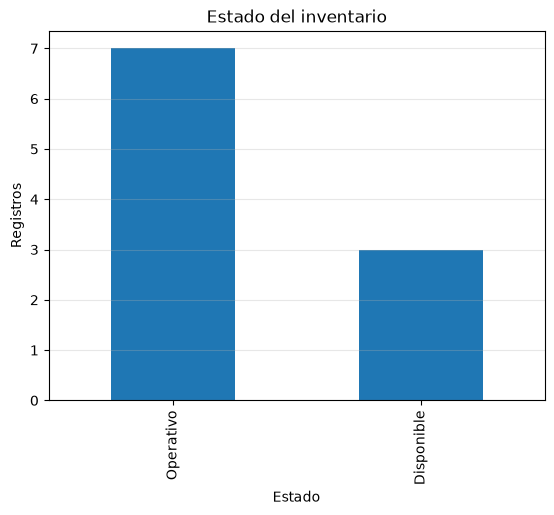

In [6]:
# Gráfico 4: estado del inventario
inv["estado"].value_counts().plot(kind="bar", title="Estado del inventario")
plt.xlabel("Estado")
plt.ylabel("Registros")
plt.grid(axis="y", alpha=.3)
plt.show()


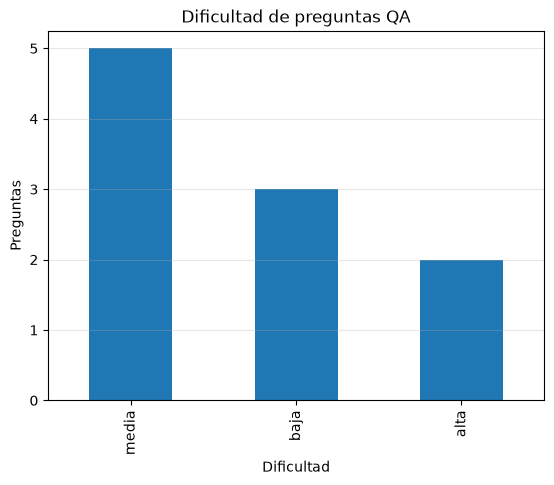

In [7]:
# Gráfico 5: dificultad del set QA
qa["difficulty"].value_counts().plot(kind="bar", title="Dificultad de preguntas QA")
plt.xlabel("Dificultad")
plt.ylabel("Preguntas")
plt.grid(axis="y", alpha=.3)
plt.show()


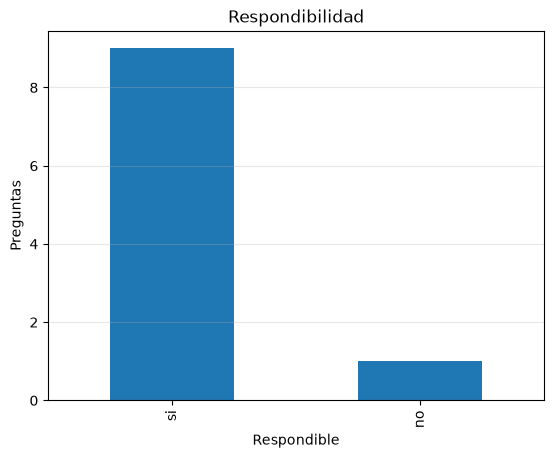

In [8]:
# Gráfico 6: preguntas respondibles/no respondibles
qa["answerable"].value_counts().plot(kind="bar", title="Respondibilidad")
plt.xlabel("Respondible")
plt.ylabel("Preguntas")
plt.grid(axis="y", alpha=.3)
plt.show()


In [9]:
print("Valores faltantes documentos:")
display(docs.isna().sum().to_frame("faltantes"))
print("Valores faltantes inventario:")
display(inv.isna().sum().to_frame("faltantes"))
print("Valores faltantes QA:")
display(qa.isna().sum().to_frame("faltantes"))


Valores faltantes documentos:


,faltantes
document_id,0
project_id,0
document_type,0
title,0
responsible_unit,0
document_date,0
version,0
section,0
chunk_id,0
text,0


Valores faltantes inventario:


,faltantes
codigo,0
descripcion,0
categoria,0
marca,0
modelo,0
cantidad,0
unidad,0
estado,0
ubicacion,0
responsable,0


Valores faltantes QA:


,faltantes
qa_id,0
question,0
category,0
expected_source_id,1
expected_answer,0
acceptable_answer,0
difficulty,0
answerable,0
notes,0


## Conclusión

El corpus sample es pequeño y está diseñado para verificar el pipeline, no para estimar desempeño operacional.
Las decisiones de preprocesamiento deben conservar identificadores, metadatos y trazabilidad de fuentes.
